In [797]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [798]:
df = pd.read_csv('ecommerce_sales_MESSY_practice.csv')

In [799]:
df.head()

,order_id,order_date,customer_id,customer_name,gender,age,email,phone,city,state,...,quantity,unit_price,discount,sales,profit,payment_method,order_status,delivery_days,customer_rating,store_channel
0,13306,1/19/2031,1963,Deepak Rao,M,50,deepak.rao1963@yahoo.com,9776024033,Mumbai,Maharashtra,...,2,205.06,0.30,287.08,40.64,COD,Delivered,5,4.8,Online
1,14543,6/9/2034,1657,Imran Das,m,45 years,imran.das1657@outlook.com,9100310298,Patna,Bihar,...,3,242.07,0.34,479.30,166.18,Wallet,Delivered,10,4.8,Online
2,14558,6/24/2034,1736,Aditya Joshi,Male,38,aditya.joshi1736@gmail.com,9879827197,Cuttack,Odisha,...,6,215.39,0.29,917.56,112.53,Card,Delivered,10,3.3,Online
3,11554,4/3/2026,1682,Amit Sharma,Male,24,amit.sharma1682@yahoo.com,9103939477,Surat,Gujarat,...,2,535.12,0.03,1038.13,151.54,Card,Delivered,6,2.0,Online
4,13909,9/13/2032,1617,Yash Bose,Male,18,yash.bose1617@outlook.com,9538512642,Bhubaneswar,Odisha,...,2,61.3,0.11,109.11,13.55,Card,Delivered,6,2.7,Online


In [800]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5120 entries, 0 to 5119
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         5120 non-null   int64  
 1   order_date       5120 non-null   str    
 2   customer_id      5120 non-null   int64  
 3   customer_name    5060 non-null   str    
 4   gender           5120 non-null   str    
 5   age              4919 non-null   str    
 6   email            5037 non-null   str    
 7   phone            5120 non-null   str    
 8   city             4967 non-null   str    
 9   state            5120 non-null   str    
 10  region           5120 non-null   str    
 11  product          5120 non-null   str    
 12  category         5120 non-null   str    
 13  quantity         5120 non-null   int64  
 14  unit_price       5120 non-null   str    
 15  discount         5019 non-null   float64
 16  sales            5120 non-null   float64
 17  profit           5069 non

In [801]:
df['order_date'] = df['order_date'].apply(pd.to_datetime)

In [802]:
df.duplicated().sum()

np.int64(120)

In [803]:
df.drop_duplicates(inplace=True)

In [804]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5119
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   int64         
 1   order_date       5000 non-null   datetime64[us]
 2   customer_id      5000 non-null   int64         
 3   customer_name    4940 non-null   str           
 4   gender           5000 non-null   str           
 5   age              4800 non-null   str           
 6   email            4920 non-null   str           
 7   phone            5000 non-null   str           
 8   city             4850 non-null   str           
 9   state            5000 non-null   str           
 10  region           5000 non-null   str           
 11  product          5000 non-null   str           
 12  category         5000 non-null   str           
 13  quantity         5000 non-null   int64         
 14  unit_price       5000 non-null   str           
 15  dis

### Fixing Age Columns   

In [805]:
df['age'].isna().sum()

np.int64(200)

In [806]:
df['age'].unique()

<StringArray>
[      '50', '45 years',       '38',       '24',       '18',       '22',
       '42',       '39',       '33',       '46',       '43',       '32',
       '26',       '28',       '27',       '35',        nan,       '36',
       '64',       '54',       '30',       '48',       '31',       '29',
       '49',       '53',       '52',       '34',       '51',       '37',
       '56',       '55',       '40',       '20',       '41',       '44',
       '19',       '45', '33 years',       '47',       '23',       '25',
       '21',      '999', '37 years', '36 years',       '57', '22 years',
        '0', '25 years', '19 years', '24 years', '34 years', '35 years',
      '150', '54 years', '31 years',       '61',       '69', '18 years',
 '69 years', '20 years', '52 years', '26 years',       '60',       '68',
 '43 years', '38 years', '50 years', '29 years',       '-1', '46 years',
 '23 years', '27 years', '51 years', '30 years']
Length: 76, dtype: str

In [807]:
df['age'] = df['age'].astype(str).str.extract(r'(\d+)')[0]

In [808]:
df['age'].unique()

<StringArray>
[ '50',  '45',  '38',  '24',  '18',  '22',  '42',  '39',  '33',  '46',  '43',
  '32',  '26',  '28',  '27',  '35',   nan,  '36',  '64',  '54',  '30',  '48',
  '31',  '29',  '49',  '53',  '52',  '34',  '51',  '37',  '56',  '55',  '40',
  '20',  '41',  '44',  '19',  '47',  '23',  '25',  '21', '999',  '57',   '0',
 '150',  '61',  '69',  '60',  '68',   '1']
Length: 50, dtype: str

In [809]:
df['age'] = pd.to_numeric(df['age'], errors='coerce')

In [810]:
df.loc[(df['age']<18) | (df['age']>80), "age"] = np.nan

In [811]:
df['age'] = df['age'].fillna(df.groupby('customer_id')['age'].transform('median'))

In [812]:
df['age'] = df['age'].astype(int)

In [813]:
df['age'].dtype

dtype('int64')

### Adding Age Groups


In [814]:
df['age'].describe()

count    5000.000000
mean       33.708600
std        10.258437
min        18.000000
25%        26.000000
50%        33.000000
75%        41.000000
max        69.000000
Name: age, dtype: float64

In [815]:
conditions = [
    (df['age'] >=18) & (df['age']<=30),
    (df['age'] >=31) & (df['age']<=45),
    (df['age'] >=46) & (df['age']<=60),
    (df['age'] >=61) & (df['age']<=100)
]
labels = ['Young','Adult','MiddelAged','SeniorCitizen']

df['age group'] = np.select(conditions,labels, default='Unknown')

df['age group'].value_counts()

age group
Adult            2318
Young            1987
MiddelAged        665
SeniorCitizen      30
Name: count, dtype: int64

# Checking City

In [816]:
print(df['city'].unique())
df['city'].nunique()

<StringArray>
[            'Mumbai',              'Patna',            'Cuttack',
              'Surat',        'Bhubaneswar',            'Gurgaon',
             'Mysuru', 'Thiruvananthapuram',             'Jaipur',
           'Mysuru  ',
 ...
             'Udipur',                'Gya',           'Bngaluru',
           'Bengaluu', 'THIRUVANANTHAPURAM',             'Cuttck',
             'JAIPUR',            'UDAIPUR',               'Pata',
              'Rachi']
Length: 198, dtype: str


197

In [817]:
df['city'] = df['city'].str.strip().str.title()


In [818]:
print(df['city'].value_counts().to_string())

city
Hyderabad             268
Ranchi                268
Jaipur                210
Udaipur               201
Cuttack               180
Faridabad             170
Amritsar              169
Gurgaon               164
Chennai               161
Bengaluru             152
Bhubaneswar           150
Delhi                 150
Patna                 147
Mumbai                145
Nagpur                145
Ludhiana              144
Mysuru                143
New Delhi             143
Thiruvananthapuram    140
Vadodara              139
Kolkata               138
Kochi                 137
Howrah                137
Surat                 136
Coimbatore            130
Ahmedabad             128
Gaya                  126
Pune                  116
Noida                  68
Kanpur                 66
Agra                   65
Lucknow                64
Japur                   4
Ahmedabd                4
Pana                    4
Kohi                    3
Kolkta                  3
Msuru                   3
Hyderaa

In [819]:
print(df['city'].value_counts().to_string())

city
Hyderabad             268
Ranchi                268
Jaipur                210
Udaipur               201
Cuttack               180
Faridabad             170
Amritsar              169
Gurgaon               164
Chennai               161
Bengaluru             152
Bhubaneswar           150
Delhi                 150
Patna                 147
Mumbai                145
Nagpur                145
Ludhiana              144
Mysuru                143
New Delhi             143
Thiruvananthapuram    140
Vadodara              139
Kolkata               138
Kochi                 137
Howrah                137
Surat                 136
Coimbatore            130
Ahmedabad             128
Gaya                  126
Pune                  116
Noida                  68
Kanpur                 66
Agra                   65
Lucknow                64
Japur                   4
Ahmedabd                4
Pana                    4
Kohi                    3
Kolkta                  3
Msuru                   3
Hyderaa

In [820]:
count = df['city'].value_counts()
correct_cities = count[count>=20].index.to_list()
correct_cities

['Hyderabad',
 'Ranchi',
 'Jaipur',
 'Udaipur',
 'Cuttack',
 'Faridabad',
 'Amritsar',
 'Gurgaon',
 'Chennai',
 'Bengaluru',
 'Bhubaneswar',
 'Delhi',
 'Patna',
 'Mumbai',
 'Nagpur',
 'Ludhiana',
 'Mysuru',
 'New Delhi',
 'Thiruvananthapuram',
 'Vadodara',
 'Kolkata',
 'Kochi',
 'Howrah',
 'Surat',
 'Coimbatore',
 'Ahmedabad',
 'Gaya',
 'Pune',
 'Noida',
 'Kanpur',
 'Agra',
 'Lucknow']

In [821]:
from difflib import get_close_matches

def fix_city(c):
    if pd.isna(c) or c in correct_cities:
        return c
    match = get_close_matches(c, correct_cities, n=1, cutoff=0.8)
    return match[0] if match else c

df['city'] = df['city'].apply(fix_city)

In [822]:
print(df['city'].unique())
df['city'].nunique()

<StringArray>
[            'Mumbai',              'Patna',            'Cuttack',
              'Surat',        'Bhubaneswar',            'Gurgaon',
             'Mysuru', 'Thiruvananthapuram',             'Jaipur',
         'Coimbatore',          'Hyderabad',             'Ranchi',
            'Udaipur',            'Kolkata',           'Ludhiana',
               'Pune',              'Kochi',           'Amritsar',
          'Faridabad',          'Ahmedabad',             'Howrah',
          'Bengaluru',             'Nagpur',          'New Delhi',
            'Chennai',               'Gaya',               'Agra',
             'Kanpur',              'Noida',           'Vadodara',
              'Delhi',                  nan,            'Lucknow']
Length: 33, dtype: str


32

In [823]:
df['city'] = df['city'].replace({
    'New Delhi' : 'Delhi',
    'Mysuru' : 'Mysore'
})

In [824]:
print(df['city'].unique())
df['city'].nunique()

<StringArray>
[            'Mumbai',              'Patna',            'Cuttack',
              'Surat',        'Bhubaneswar',            'Gurgaon',
             'Mysore', 'Thiruvananthapuram',             'Jaipur',
         'Coimbatore',          'Hyderabad',             'Ranchi',
            'Udaipur',            'Kolkata',           'Ludhiana',
               'Pune',              'Kochi',           'Amritsar',
          'Faridabad',          'Ahmedabad',             'Howrah',
          'Bengaluru',             'Nagpur',              'Delhi',
            'Chennai',               'Gaya',               'Agra',
             'Kanpur',              'Noida',           'Vadodara',
                  nan,            'Lucknow']
Length: 32, dtype: str


31

### Fix States

In [825]:
df['state'].unique()


<StringArray>
[   'Maharashtra',         ' Bihar',         'Odisha',        'Gujarat',
        'Haryana',      'Karnataka',         'Kerala',      'Rajasthan',
     'Tamil Nadu',    'MAHARASHTRA',      'Telangana',      'Jharkhand',
    'West Bengal',         'Punjab',          'Bihar',          'Delhi',
  'Uttar Pradesh',         ' Delhi',     ' Rajasthan',         'Delhi ',
          'bihar',  'uttar pradesh',     'Jharkhand ',     'Karnataka ',
      'JHARKHAND',     'Telangana ',   ' West Bengal',       ' Gujarat',
        ' Kerala',         'punjab',   ' Maharashtra',     ' Jharkhand',
      'rajasthan',         'kerala',        'gujarat',     'TAMIL NADU',
     ' Telangana', 'Uttar Pradesh ',      'TELANGANA',    ' Tamil Nadu',
      'KARNATAKA',     'Rajasthan ',          'BIHAR', ' Uttar Pradesh',
         'odisha',    'maharashtra',    'WEST BENGAL',        'GUJARAT',
         'KERALA',      'karnataka',      'telangana',       ' Haryana',
       'Gujarat ',          'DELHI', 

In [826]:
df['state'] = df['state'].str.strip().str.title()

In [827]:
df['state'].unique()

<StringArray>
[  'Maharashtra',         'Bihar',        'Odisha',       'Gujarat',
       'Haryana',     'Karnataka',        'Kerala',     'Rajasthan',
    'Tamil Nadu',     'Telangana',     'Jharkhand',   'West Bengal',
        'Punjab',         'Delhi', 'Uttar Pradesh',    'Westbengal',
     'Tamilnadu',  'Uttarpradesh']
Length: 18, dtype: str

In [828]:
df['state'] = df['state'].replace({
    'Westbengal': 'West Bengal',
    'Tamilnadu' : 'Tamil Nadu',
    'Uttarpradesh' : 'Uttar Pradesh'
})

In [829]:
df['state'].nunique()

15

### filling cities name by using most common cities in states(guess)

In [830]:
df['city'].isna().sum()

np.int64(150)

In [831]:
df['city'] = df['city'].fillna(
    df.groupby('state')['city'].transform(lambda x: x.mode()[0] if not x.mode().empty else None)
)

In [832]:
df['city'].isna().sum()

np.int64(0)

#### Fixing Ratings

In [833]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'email', 'phone', 'city', 'state', 'region', 'product',
       'category', 'quantity', 'unit_price', 'discount', 'sales', 'profit',
       'payment_method', 'order_status', 'delivery_days', 'customer_rating',
       'store_channel', 'age group'],
      dtype='str')

In [834]:
df['customer_rating'].isna().sum()

np.int64(250)

In [835]:
df['customer_rating'].describe()

count    4750.000000
mean        2.969389
std         1.157101
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: customer_rating, dtype: float64

In [836]:
customer_rating_mean = df['customer_rating'].mean()
df['customer_rating'] = df['customer_rating'].fillna(customer_rating_mean)

In [837]:
df['customer_rating'].isna().sum()

np.int64(0)

#### fixing payment methods


In [838]:
df['payment_method'].value_counts()

payment_method
Card                2128
COD                 1636
Wallet               886
CARD                  39
C.O.D                 36
Cash on Delivery      36
card                  32
cod                   29
Credit Card           28
wallet                18
WALLET                17
E-Wallet              15
Name: count, dtype: int64

In [839]:
count = df['payment_method'].value_counts()
correct_payment_method = count[count>=800].index.tolist()
correct_payment_method

['Card', 'COD', 'Wallet']

In [840]:
from difflib import get_close_matches
def fix_payments(p):
    if p in correct_payment_method or pd.isna(p):
        return p
    match = get_close_matches(p, correct_payment_method, n=1, cutoff= 0.8)
    return match[0] if match else None

df['payment_method'] = df['payment_method'].apply(fix_payments)


In [841]:
df['payment_method'].unique()

<StringArray>
['COD', 'Wallet', 'Card', nan]
Length: 4, dtype: str

In [842]:
df['payment_method'].value_counts()

payment_method
Card      2128
COD       1636
Wallet     919
Name: count, dtype: int64

In [843]:
df['payment_method'].isna().sum()

np.int64(317)

In [844]:
probs = df['payment_method'].value_counts(normalize=True)

In [845]:
missing = df['payment_method'].isna()

In [846]:
df.loc[missing, 'payment_method'] = np.random.choice(
    probs.index , size = missing.sum(), p = probs.values
)

In [847]:
df['payment_method'].value_counts()

payment_method
Card      2264
COD       1745
Wallet     991
Name: count, dtype: int64

#### Fixing Genders


In [848]:
df['gender'].value_counts()

gender
Female    1668
Male      1582
M          238
f          225
female     225
F          220
m          213
male       213
MALE       212
FEMALE     204
Name: count, dtype: int64

In [849]:
df['gender'] = df['gender'].replace({
    'M' : "Male",
    'm' : "Male",
    'male' : "Male",
    'MALE' : "Male",
    'f' : 'Female',
    'female' : 'Female',
    'F' : 'Female',
    'FEMALE' : 'Female',
})

In [850]:
df['gender'].value_counts()

gender
Female    2542
Male      2458
Name: count, dtype: int64

In [851]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5119
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   int64         
 1   order_date       5000 non-null   datetime64[us]
 2   customer_id      5000 non-null   int64         
 3   customer_name    4940 non-null   str           
 4   gender           5000 non-null   str           
 5   age              5000 non-null   int64         
 6   email            4920 non-null   str           
 7   phone            5000 non-null   str           
 8   city             5000 non-null   str           
 9   state            5000 non-null   str           
 10  region           5000 non-null   str           
 11  product          5000 non-null   str           
 12  category         5000 non-null   str           
 13  quantity         5000 non-null   int64         
 14  unit_price       5000 non-null   str           
 15  dis

In [852]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5119
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   int64         
 1   order_date       5000 non-null   datetime64[us]
 2   customer_id      5000 non-null   int64         
 3   customer_name    4940 non-null   str           
 4   gender           5000 non-null   str           
 5   age              5000 non-null   int64         
 6   email            4920 non-null   str           
 7   phone            5000 non-null   str           
 8   city             5000 non-null   str           
 9   state            5000 non-null   str           
 10  region           5000 non-null   str           
 11  product          5000 non-null   str           
 12  category         5000 non-null   str           
 13  quantity         5000 non-null   int64         
 14  unit_price       5000 non-null   str           
 15  dis

In [853]:
df["unit_price"] = pd.to_numeric(
    df["unit_price"].astype(str).str.replace(r"[^\d.]", "", regex=True),
    errors="coerce"
)
df.loc[df["unit_price"] > 1000, "unit_price"] = np.nan
df["unit_price"] = df["unit_price"].fillna(df["unit_price"].median().round(2))

In [854]:
df.loc[(df["quantity"] < 1) | (df["quantity"] > 10), "quantity"] = np.nan
df["quantity"] = df["quantity"].fillna(df["quantity"].median()).astype(int)

In [855]:
# Clean the discount values first
pct = df["discount"].between(2, 35)                  # 35 means 35%
df.loc[pct, "discount"] = df.loc[pct, "discount"] / 100
df.loc[(df["discount"] < 0) | (df["discount"] > 0.35), "discount"] = np.nan

q_p = df["quantity"] * df["unit_price"]
known = df["discount"].notna()

# Known discount: fix the wrong sales
expected = (q_p * (1 - df["discount"])).round(2)
wrong_sales = known & ((df["sales"] - expected).abs() > 1)
print("sales fixed:", wrong_sales.sum())             # about 100
df.loc[wrong_sales, "sales"] = expected[wrong_sales]

# Missing discount: calculate it from sales
derived = (1 - df["sales"] / q_p).round(2)
ok = (~known) & derived.between(0, 0.35)
df.loc[ok, "discount"] = derived[ok]

# Leftover rows: median discount, then recalculate sales
left = df["discount"].isna()
df.loc[left, "discount"] = df["discount"].median().round(2)
df.loc[left, "sales"] = (q_p[left] * (1 - df.loc[left, "discount"])).round(2)

# Final check
print("mismatch:", ((df["sales"] - q_p * (1 - df["discount"])).abs() > 1).sum())   # 0
print(df[["unit_price", "quantity", "discount", "sales"]].isna().sum())            # all 0

sales fixed: 161
mismatch: 0
unit_price    0
quantity      0
discount      0
sales         0
dtype: int64


In [856]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'email', 'phone', 'city', 'state', 'region', 'product',
       'category', 'quantity', 'unit_price', 'discount', 'sales', 'profit',
       'payment_method', 'order_status', 'delivery_days', 'customer_rating',
       'store_channel', 'age group'],
      dtype='str')

In [857]:
df.drop(columns=['email'], inplace=True)

### Fixed DElivery Days

In [858]:
df['delivery_days'].value_counts()

delivery_days
 10     491
 6      479
 7      475
 4      471
 8      468
 11     465
 9      454
 1      439
 2      419
 5      410
 3      409
 90       9
-3        8
 365      3
Name: count, dtype: int64

In [859]:
df.loc[(df['delivery_days'] < 0) | (df['delivery_days']>=90), 'delivery_days'] = np.nan

In [860]:
df['delivery_days'] = df['delivery_days'].fillna(df['delivery_days'].mean()).astype(int)

In [861]:
df['delivery_days'].value_counts().sort_values

<bound method Series.sort_values of delivery_days
6     499
10    491
7     475
4     471
8     468
11    465
9     454
1     439
2     419
5     410
3     409
Name: count, dtype: int64>

In [862]:
print(df["delivery_days"].isna().sum())

0


In [863]:
print(df["delivery_days"].describe()) 

count    5000.000000
mean        6.122400
std         3.146522
min         1.000000
25%         3.000000
50%         6.000000
75%         9.000000
max        11.000000
Name: delivery_days, dtype: float64


In [864]:
df.drop(columns = ['phone'], inplace = True)

In [865]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'city', 'state', 'region', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'sales', 'profit', 'payment_method',
       'order_status', 'delivery_days', 'customer_rating', 'store_channel',
       'age group'],
      dtype='str')

In [866]:
df['category'].value_counts()

category
Electronics     1669
Clothing        1440
Home             907
Beauty           684
electronics       40
 Electronics      36
clothing          35
ELECTRONICS       32
CLOTHING          31
 Clothing         25
home              22
HOME              20
 Home             20
 Beauty           14
BEAUTY            13
beauty            12
Name: count, dtype: int64

In [867]:
df['category'] = df['category'].str.strip().str.title()


In [868]:
df['category'].unique()

<StringArray>
['Clothing', 'Beauty', 'Electronics', 'Home']
Length: 4, dtype: str

In [869]:
df['store_channel'].unique()

<StringArray>
['Online']
Length: 1, dtype: str

In [870]:
df['order_status'].unique()

<StringArray>
['Delivered',  'Returned', 'Cancelled',   'Pending',   'Shipped', 'DELIVERED',
  'Deliverd', 'delivered',    'Shiped',   'Retured', 'CANCELLED',   'pending',
   'shipped',   'PENDING',  'returned', 'cancelled',  'Canceled']
Length: 17, dtype: str

In [871]:
df['order_status'] = df['order_status'].str.strip().str.title()

In [872]:
df['order_status'].unique()

<StringArray>
['Delivered',  'Returned', 'Cancelled',   'Pending',   'Shipped',  'Deliverd',
    'Shiped',   'Retured',  'Canceled']
Length: 9, dtype: str

In [873]:
df['order_status'] = df['order_status'].replace({
    'Deliverd' : 'Delivered',
    'Shiped' : 'Shipped',
    'Canceled' : 'Cancelled',
    'Retured' : 'Returned'
})

In [874]:
df['order_status'].unique()

<StringArray>
['Delivered', 'Returned', 'Cancelled', 'Pending', 'Shipped']
Length: 5, dtype: str

In [875]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5119
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   int64         
 1   order_date       5000 non-null   datetime64[us]
 2   customer_id      5000 non-null   int64         
 3   customer_name    4940 non-null   str           
 4   gender           5000 non-null   str           
 5   age              5000 non-null   int64         
 6   city             5000 non-null   str           
 7   state            5000 non-null   str           
 8   region           5000 non-null   str           
 9   product          5000 non-null   str           
 10  category         5000 non-null   str           
 11  quantity         5000 non-null   int64         
 12  unit_price       5000 non-null   float64       
 13  discount         5000 non-null   float64       
 14  sales            5000 non-null   float64       
 15  pro

### Filling Profit

In [876]:
ratio = df['profit'] / df['sales']
ratio

0       0.141563
1       0.346714
2       0.122640
3       0.145974
4       0.124187
          ...   
5115    0.177051
5116    0.219850
5117    0.197033
5118    0.197240
5119    0.171467
Length: 5000, dtype: float64

In [877]:
margin = ratio.groupby([df['category'], df['order_status']]).transform('median')
margin

0       0.251566
1       0.296806
2       0.124724
3       0.211913
4       0.124724
          ...   
5115    0.251566
5116    0.251566
5117    0.211913
5118    0.296806
5119    0.124724
Length: 5000, dtype: float64

In [878]:
df['profit'] = df['profit'].fillna(round(df['sales']*margin,2))

In [879]:
print(df["profit"].isna().sum())

0


In [880]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5119
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5000 non-null   int64         
 1   order_date       5000 non-null   datetime64[us]
 2   customer_id      5000 non-null   int64         
 3   customer_name    4940 non-null   str           
 4   gender           5000 non-null   str           
 5   age              5000 non-null   int64         
 6   city             5000 non-null   str           
 7   state            5000 non-null   str           
 8   region           5000 non-null   str           
 9   product          5000 non-null   str           
 10  category         5000 non-null   str           
 11  quantity         5000 non-null   int64         
 12  unit_price       5000 non-null   float64       
 13  discount         5000 non-null   float64       
 14  sales            5000 non-null   float64       
 15  pro

In [881]:
df.to_csv('ecommerce_sales_clean.csv', index=False)

# Data Analysis


In [882]:
df_copy = df.copy()

In [883]:
df_copy.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'city', 'state', 'region', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'sales', 'profit', 'payment_method',
       'order_status', 'delivery_days', 'customer_rating', 'store_channel',
       'age group'],
      dtype='str')

In [884]:
valid = df[df['order_status'] != 'Cancelled']

### KPI's

In [885]:
# Total Sales 
total_sales = valid['sales'].sum()
print("Total Sales = ", total_sales)

Total Sales =  4775944.39


In [886]:
# total profit
total_profit = valid['profit'].sum().round(2)
print('Total Profit =',total_profit )

Total Profit = 906240.36


In [887]:
# cost price
total_cost_price = (valid['sales'] - valid['profit']).sum().round(2)
print("Total Cost Price = ",total_cost_price)

Total Cost Price =  3869704.03


In [888]:
profit_margin = (total_profit/total_sales)*100
print('Profit Margin = ', round(profit_margin,2), "%")

Profit Margin =  18.98 %


In [889]:
cancel_rate = (df['order_status'] == 'Cancelled').mean()*100
print("Cancellation Percentage = ",cancel_rate, "%")

Cancellation Percentage =  6.38 %


In [890]:
returned_rate = (df['order_status']=="Returned").mean()*100
print("Returned Percentage = ",returned_rate, "%")

Returned Percentage =  5.3 %


#### customers analysis

In [891]:
# Number of Customers
total_customers = valid['customer_id'].nunique()
print("Total Customers = ", total_customers)

Total Customers =  984


In [892]:
#ARPU
arpu = valid['sales'].mean().round(2)
print('Avg sale per customer = ', arpu)

Avg sale per customer =  1020.28


In [893]:
# Top customers
top_customers = valid.groupby(['customer_id','customer_name'])['sales'].sum().nlargest(5)
top_customers

customer_id  customer_name
1663         Meera Chopra     15606.06
1276         Komal Khan       14611.56
1955         Shreya Sharma    14200.76
1675         Aisha Ansari     14068.22
1957         Priya Chopra     13810.99
Name: sales, dtype: float64

#### Delivery Days Analysis

In [894]:
# Average Delivery Days
avg_delivery_days = valid['delivery_days'].mean()
avg_delivery_days = avg_delivery_days.astype(int)
print("Average Delivery Days = ",avg_delivery_days)

Average Delivery Days =  6


In [895]:
#Average Delivery Days per state
avg_days = valid.groupby('state')['delivery_days'].mean().sort_values(ascending=False)
avg_days.astype(int).reset_index()


,state,delivery_days
0,Karnataka,6
1,Delhi,6
2,Uttar Pradesh,6
3,Odisha,6
4,Tamil Nadu,6
5,Maharashtra,6
6,Bihar,6
7,West Bengal,6
8,Kerala,6
9,Gujarat,6


In [923]:
#Average Delivery Days per state & city
avg_days = valid.groupby(['state', 'city'])['delivery_days'].mean().sort_values(ascending=False)
avg_days.astype(int).reset_index()


,state,city,delivery_days
0,Uttar Pradesh,Lucknow,7
1,Tamil Nadu,Coimbatore,6
2,Punjab,Ludhiana,6
3,Karnataka,Bengaluru,6
4,Karnataka,Mysore,6
5,Gujarat,Surat,6
6,Odisha,Bhubaneswar,6
7,Uttar Pradesh,Kanpur,6
8,Maharashtra,Mumbai,6
9,Maharashtra,Pune,6


In [928]:
# Delivery Days based on products
valid.groupby(['category','product'])['delivery_days'].mean()

category     product          
Beauty       Face Wash            5.773109
             Hair Serum           6.549669
             Lipstick             6.206612
             Moisturizer          6.234483
             Perfume              6.338028
Clothing     Jacket               6.069869
             Jeans                6.420354
             Kurta                6.506276
             Men's T-Shirt        5.909465
             Saree                5.777778
             Sneakers             6.227273
Electronics  Bluetooth Speaker    6.244526
             Laptop               6.162963
             Power Bank           6.303887
             Smart Watch          5.741573
             Smartphone           5.986711
             Wireless Earbuds     6.116105
Home         Bedsheet Set         6.208791
             Cookware Set         6.345455
             Mixer Grinder        6.022099
             Table Lamp           6.301075
             Wall Clock           6.000000
Name: delivery_days, dt

#### Customer Rating Analysis


In [897]:
avg_ratings = valid['customer_rating'].mean()
print(round(avg_ratings,2))

2.97


In [930]:
#customer rating by producs and category
valid.groupby(['category','product'])['customer_rating'].mean()

category     product          
Beauty       Face Wash            3.163094
             Hair Serum           2.890580
             Lipstick             2.991297
             Moisturizer          3.116664
             Perfume              2.925898
Clothing     Jacket               3.070653
             Jeans                3.178057
             Kurta                2.980343
             Men's T-Shirt        2.993391
             Saree                2.923907
             Sneakers             2.906333
Electronics  Bluetooth Speaker    2.960085
             Laptop               3.027733
             Power Bank           2.878618
             Smart Watch          2.947313
             Smartphone           2.934891
             Wireless Earbuds     2.895918
Home         Bedsheet Set         2.926890
             Cookware Set         2.984391
             Mixer Grinder        2.980967
             Table Lamp           2.915394
             Wall Clock           2.875677
Name: customer_rating, 

In [947]:
valid.groupby(['state','city'])['customer_rating'].mean().round(2).reset_index()

,state,city,customer_rating
0,Bihar,Gaya,2.80
1,Bihar,Patna,3.06
2,Delhi,Delhi,3.04
3,Gujarat,Ahmedabad,2.97
4,Gujarat,Surat,3.03
5,Gujarat,Vadodara,2.81
6,Haryana,Faridabad,3.06
7,Haryana,Gurgaon,3.03
8,Jharkhand,Ranchi,2.96
9,Karnataka,Bengaluru,2.98


### Age group Analysis

In [932]:
#Total Customers by Age group
customerByAge = valid.groupby('age group')['customer_id'].count().reset_index()
customerByAge.columns =['age group','Total customer']
customerByAge


,age group,Total customer
0,Adult,2157
1,MiddelAged,627
2,SeniorCitizen,27
3,Young,1870


In [938]:
#Category purchased according to age group
categoryByAges =  valid.groupby(['category','age group']).size().reset_index()

categoryByAges

,category,age group,0
0,Beauty,Adult,309
1,Beauty,MiddelAged,95
2,Beauty,SeniorCitizen,5
3,Beauty,Young,269
4,Clothing,Adult,657
5,Clothing,MiddelAged,190
6,Clothing,SeniorCitizen,7
7,Clothing,Young,577
8,Electronics,Adult,765
9,Electronics,MiddelAged,219


### Product & Category Sales

In [952]:
#sale of product and category
sales = valid.groupby(['category','product'])['sales'].agg(['count','sum'])
sales.columns = ['Count of Sales', 'Total Sales']
sales

Count of Sales  Total Sales
category    product                                       
Beauty      Face Wash                     119    140060.42
            Hair Serum                    151    157668.54
            Lipstick                      121    117524.01
            Moisturizer                   145    167286.00
            Perfume                       142    137168.25
Clothing    Jacket                        229    240459.31
            Jeans                         226    214918.29
            Kurta                         239    234106.98
            Men's T-Shirt                 243    249716.72
            Saree                         252    253266.13
            Sneakers                      242    231337.07
Electronics Bluetooth Speaker             274    284533.24
            Laptop                        270    268830.62
            Power Bank                    283    286736.10
            Smart Watch                   267    289442.55
            Smartphone                    301    297321.49
            Wireless Earbuds              267    294015.99
Home        Bedsheet Set                  182    171879.67
            Cookware Set                  165    166158.13
            Mixer Grinder                 181    183133.62
            Table Lamp                    186    198071.32
            Wall Clock                    196    192309.94

In [939]:
# count, profit, profit-margin and sales according to category

valid.groupby('category').agg(
    orders = ('order_id', 'count'),
    sales = ('sales', 'sum'),
    profit = ('profit', 'sum')
).assign(profit_margin = lambda x: (x['profit']/x['sales']*100).round(2)).sort_values(by='sales', ascending = False)

,orders,sales,profit,profit_margin
category,,,,
Electronics,1662,1720879.99,189946.53,11.04
Clothing,1431,1423804.50,329367.81,23.13
Home,910,911552.68,180996.78,19.86
Beauty,678,719707.22,205929.24,28.61


In [958]:
# Sales of category acc. to gender
valid.groupby(['category','gender']).agg(
    orders = ('order_id','count'),
    customers = ('customer_id', 'count'),
    sales = ('sales','sum'),
    profit = ('profit','sum'),
).assign(profit_margin = lambda x : (x['profit']/x['sales']*100).round(2))

orders  customers      sales     profit  profit_margin
category    gender                                                        
Beauty      Female     338        338  352291.35  102527.83          29.10
            Male       340        340  367415.87  103401.41          28.14
Clothing    Female     746        746  751672.17  178660.03          23.77
            Male       685        685  672132.33  150707.78          22.42
Electronics Female     822        822  856871.53   93151.36          10.87
            Male       840        840  864008.46   96795.17          11.20
Home        Female     463        463  465129.88   90783.15          19.52
            Male       447        447  446422.80   90213.63          20.21

### Pivot Tables

In [901]:
pivot = pd.pivot_table(
    data = valid,
    index = 'category',
    values = ['order_id','sales','profit'],
    aggfunc={
        'order_id' : 'nunique',
        'sales' : 'sum',
        'profit' : 'sum'
    }
).sort_values(by='sales',ascending=False)
pivot

,order_id,profit,sales
category,,,
Electronics,1662,189946.53,1720879.99
Clothing,1431,329367.81,1423804.50
Home,910,180996.78,911552.68
Beauty,678,205929.24,719707.22


In [960]:

pivot_table = pd.pivot_table(
    data = valid,
    index='state',
    values=['sales','order_id','customer_id'],
    aggfunc={
        'sales' : 'sum',
        'order_id' : 'nunique',
        'customer_id' : 'nunique'
    }
).assign(repeated_orders = lambda x: (x['order_id']-x['customer_id'])).sort_values(by='sales', ascending=False)

pivot_table

,customer_id,order_id,sales,repeated_orders
state,,,,
Maharashtra,341,411,454030.01,70
Rajasthan,328,404,427598.46,76
Gujarat,325,395,381782.83,70
Haryana,266,325,326239.73,59
Odisha,279,322,312306.34,43
Karnataka,252,290,307314.46,38
Punjab,272,312,304297.58,40
West Bengal,248,288,302842.35,40
Kerala,249,283,298316.77,34


### Sales analysation by years


In [903]:
valid['year'] = pd.to_datetime(valid['order_date']).dt.to_period("Y")

In [963]:
sales_by_year = valid.groupby('year').agg(
    orders = ('order_id', 'count'),
    sales = ('sales', 'sum'),
    profit = ('profit', 'sum'),
).assign(profit_margin = lambda x : (x['profit']/x['sales']*100).round(2)).sort_values(by='sales', ascending=False)
sales_by_year.reset_index()

,year,orders,sales,profit,profit_margin
0,2033,342,376252.94,74097.11,19.69
1,2030,346,370808.89,66775.38,18.01
2,2032,349,370734.20,76292.78,20.58
3,2026,340,359994.78,66369.71,18.44
4,2027,338,357766.68,67280.08,18.81
5,2028,342,347343.39,62783.89,18.08
6,2024,343,346244.31,61868.29,17.87
7,2034,346,343106.52,69757.30,20.33
8,2023,343,341597.31,62347.12,18.25
9,2022,339,340870.51,68390.67,20.06


# Data Visualisation

<Figure size 640x480 with 0 Axes>

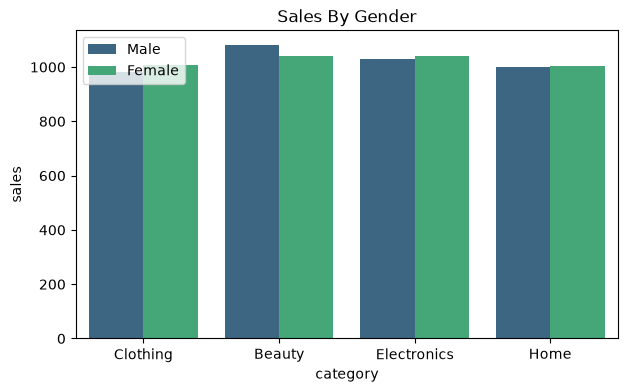

In [978]:
df_copy.groupby('gender')['sales'].sum()

plt.tight_layout()
plt.figure(figsize=(7,4))
sns.barplot(x =valid['category'] , y = valid['sales'],hue=valid['gender'], palette='viridis', errorbar=None)
plt.title("Sales By Gender")
plt.legend(loc = 'upper left')

Sales by Age Group

<Axes: xlabel='sales', ylabel='age group'>

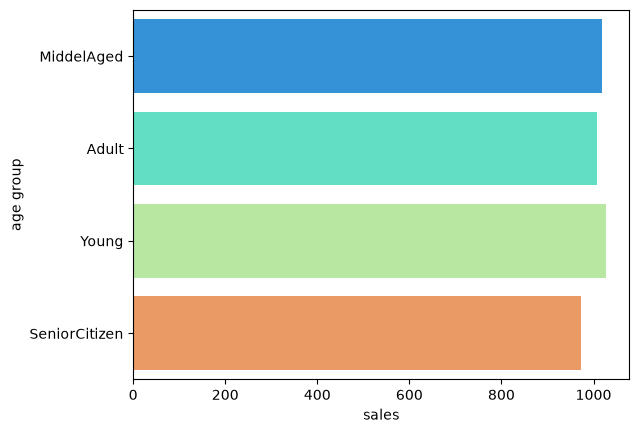

In [979]:
df.groupby('age group')['sales'].mean()

sns.barplot(x = df['sales'], y = df['age group'], palette='rainbow', errorbar=None)

<Axes: xlabel='sales', ylabel='age group'>

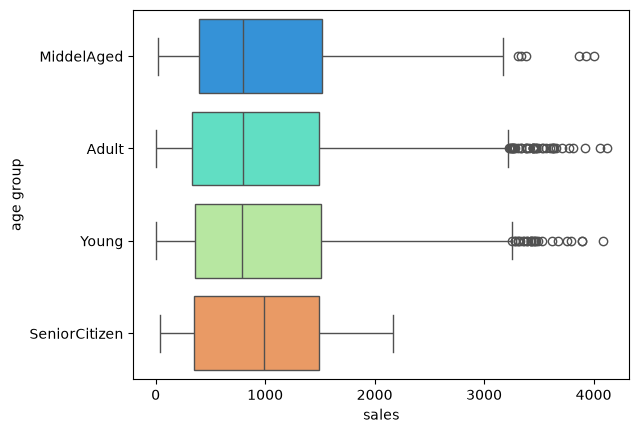

In [954]:
sns.boxplot(x=df['sales'], y=df['age group'], data=df_copy, palette='rainbow')

In [909]:
numerical_cols = df_copy.select_dtypes(include='number').columns.tolist()
print(numerical_cols)

['order_id', 'customer_id', 'age', 'quantity', 'unit_price', 'discount', 'sales', 'profit', 'delivery_days', 'customer_rating']


In [910]:
df_copy.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'city', 'state', 'region', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'sales', 'profit', 'payment_method',
       'order_status', 'delivery_days', 'customer_rating', 'store_channel',
       'age group'],
      dtype='str')

In [911]:
df_copy['gender'] = df_copy['gender'].map({
    'Male' : 0,
    'Female' : 1
})

In [912]:
numerical_cols =['gender', 'age', 'quantity', 'unit_price', 'discount', 'sales', 'profit', 'delivery_days', 'customer_rating']

<Axes: >

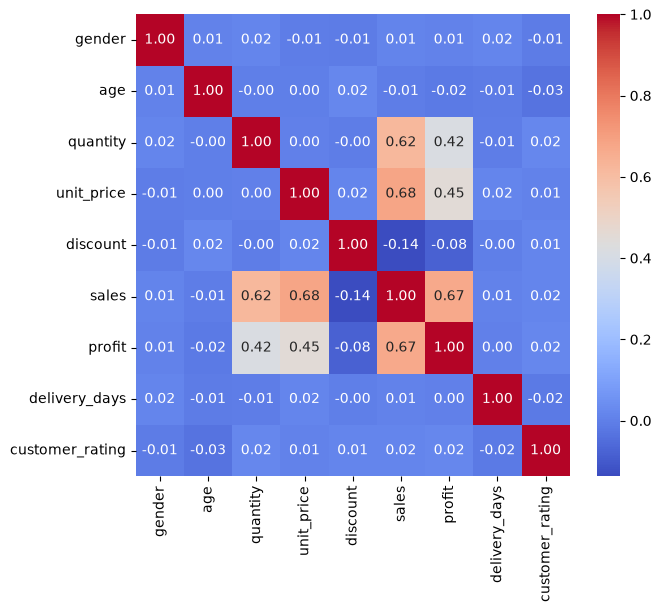

In [914]:
plt.figure(figsize=(7, 6))
sns.heatmap(df_copy[numerical_cols].corr(), annot = True, cmap='coolwarm', fmt='.2f')

In [915]:
df_copy.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'city', 'state', 'region', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'sales', 'profit', 'payment_method',
       'order_status', 'delivery_days', 'customer_rating', 'store_channel',
       'age group'],
      dtype='str')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'Maharashtra'),
  Text(1, 0, 'Bihar'),
  Text(2, 0, 'Odisha'),
  Text(3, 0, 'Gujarat'),
  Text(4, 0, 'Haryana'),
  Text(5, 0, 'Karnataka'),
  Text(6, 0, 'Kerala'),
  Text(7, 0, 'Rajasthan'),
  Text(8, 0, 'Tamil Nadu'),
  Text(9, 0, 'Jharkhand'),
  Text(10, 0, 'West Bengal'),
  Text(11, 0, 'Punjab'),
  Text(12, 0, 'Telangana'),
  Text(13, 0, 'Delhi'),
  Text(14, 0, 'Uttar Pradesh')])

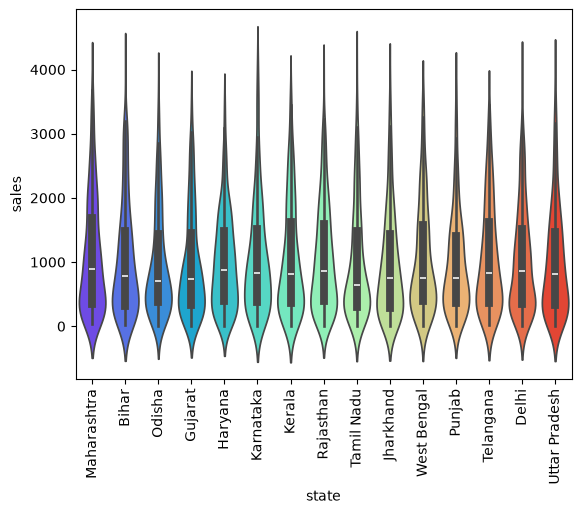

In [987]:
order = df_copy.groupby('state')['sales'].mean().sort_values(ascending=False)
sns.violinplot(data = valid, x='state', y='sales', palette='rainbow')
plt.xticks(rotation = 90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'Maharashtra'),
  Text(1, 0, 'Rajasthan'),
  Text(2, 0, 'Telangana'),
  Text(3, 0, 'Kerala'),
  Text(4, 0, 'West Bengal'),
  Text(5, 0, 'Karnataka'),
  Text(6, 0, 'Bihar'),
  Text(7, 0, 'Haryana'),
  Text(8, 0, 'Uttar Pradesh'),
  Text(9, 0, 'Delhi'),
  Text(10, 0, 'Punjab'),
  Text(11, 0, 'Tamil Nadu'),
  Text(12, 0, 'Odisha'),
  Text(13, 0, 'Gujarat'),
  Text(14, 0, 'Jharkhand')])

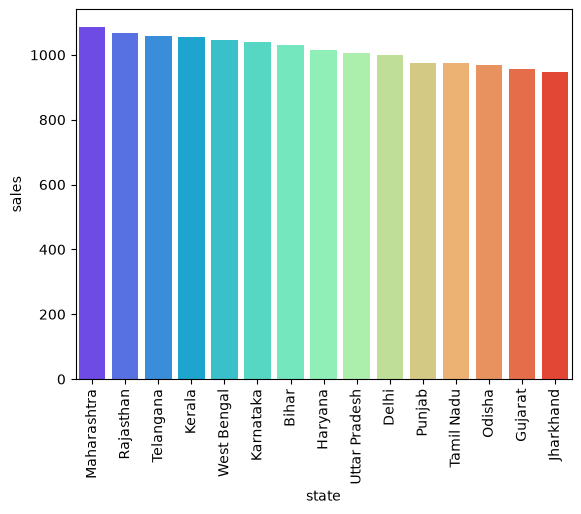

In [984]:
order = df_copy.groupby('state')['sales'].mean().sort_values(ascending=False).index
sns.barplot(data  = df_copy, x='state', y='sales', palette='rainbow', order=order, errorbar=None)
plt.xticks(rotation = 90)

In [918]:
df_copy.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_name', 'gender',
       'age', 'city', 'state', 'region', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'sales', 'profit', 'payment_method',
       'order_status', 'delivery_days', 'customer_rating', 'store_channel',
       'age group'],
      dtype='str')

In [919]:
df_copy = df_copy.drop(columns = 'store_channel')

<Axes: title={'center': 'Sales by Payment Method'}, xlabel='sales', ylabel='payment_method'>

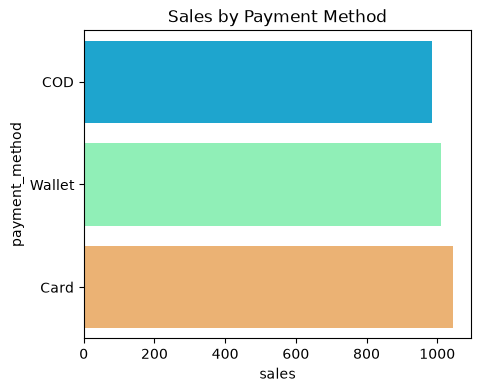

In [920]:
# Sales by Payment method
plt.figure(figsize=(5,4))
plt.title('Sales by Payment Method')
sns.barplot(data = df_copy, x='sales', y='payment_method', palette='rainbow', errorbar=None)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Delhi'),
  Text(1, 0, 'Hyderabad'),
  Text(2, 0, 'Ranchi'),
  Text(3, 0, 'Udaipur'),
  Text(4, 0, 'Jaipur'),
  Text(5, 0, 'Mumbai'),
  Text(6, 0, 'Cuttack'),
  Text(7, 0, 'Faridabad'),
  Text(8, 0, 'Kolkata'),
  Text(9, 0, 'Amritsar')])

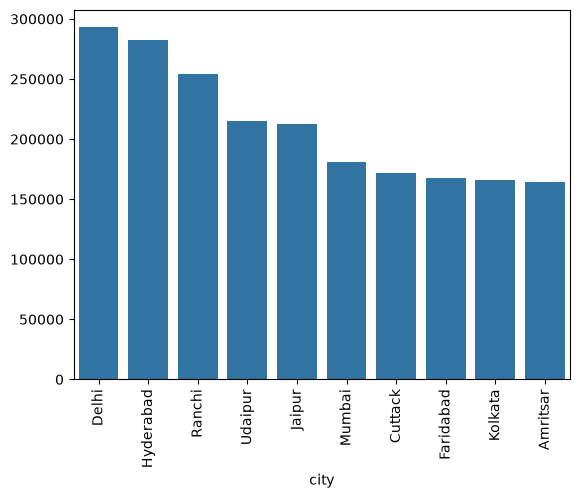

In [992]:
# Sales in city
sales_city = valid.groupby('city')['sales'].sum().sort_values(ascending=False).head(10)
sns.barplot(x = sales_city.index , y = sales_city.values)
plt.xticks(rotation = 90)

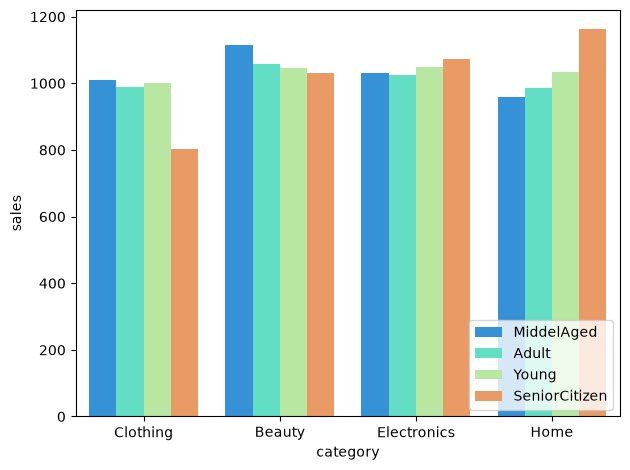

In [996]:
sns.barplot(data = valid, x = 'category', y='sales', hue = 'age group', palette='rainbow', errorbar=None )
plt.legend(loc = 'lower right')
plt.tight_layout()